# Práctica 3: Manuel Alejandro Serrano Macias
# TCOR

In [57]:
# Lectura de Datos

In [58]:
import os
import re

def get_texts_from_file(path_corpus, path_truth):
  tr_txt = []
  tr_y = []

  with open(path_corpus, "r", encoding="utf-8") as f_corpus, open (path_truth, "r", encoding="utf-8") as f_truth:

    for twitt in f_corpus:
      tr_txt += [twitt]
    
    for label in f_truth:
      tr_y += [label]

  return tr_txt, tr_y

In [59]:
tr_txt, tr_y = get_texts_from_file("./mex20_train.txt","./mex20_train_labels.txt")

In [60]:
# Estadisticas

Counter({0: 3759, 1: 1519})


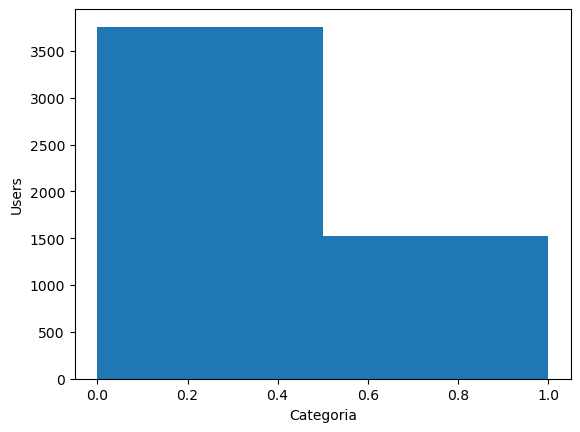

In [61]:
tr_y = list(map(int, tr_y))

from collections import Counter
import matplotlib.pyplot as plt
%matplotlib inline

print(Counter(tr_y))
plt.hist(tr_y, bins=len(set(tr_y)))
plt.ylabel("Users")
plt.xlabel("Categoria")
plt.show()

In [62]:
# Tokenización

In [63]:
import nltk
from nltk.tokenize import TweetTokenizer
tokenizer = TweetTokenizer()

corpus_palabras = []
for doc in tr_txt:
  corpus_palabras += tokenizer.tokenize(doc)

fdist = nltk.FreqDist(corpus_palabras)

In [64]:
len(corpus_palabras)

97473

In [65]:
def sortFreqDist(freqdict): 
  aux = [(freqdict[key], key) for key in freqdict]
  aux.sort()
  aux.reverse()
  return aux

In [66]:
V = sortFreqDist(fdist)
V = V[:5000]

In [67]:
dict_indices = dict()
count = 0
for weight, word in V:
  dict_indices[word] = count
  count += 1

In [68]:
import numpy as np

def build_bow_tr(tr_txt, V, dict_indices):
  BOW = np.zeros((len(tr_txt), len(V)), dtype=int)
  count_doc = 0
  for tr in tr_txt:
    fdist_doc = nltk.FreqDist(tokenizer.tokenize(tr.lower()))
    for word in fdist_doc:
      if word in dict_indices:
        # BOW[count_doc, dict_indices[word]] = 1
        BOW[count_doc, dict_indices[word]] = fdist_doc[word]
    count_doc += 1

  return BOW

In [69]:
BOW_tr = build_bow_tr(tr_txt, V, dict_indices)

In [70]:
BOW_tr.shape

(5278, 5000)

## TCOR

In [71]:
def compute_tcor(BOW):
  # Distributional Term Representation
  DTR = np.zeros((BOW.shape[1],BOW.shape[1]), dtype = int)

  # Recorrer cada tuit en BOW
  for doc, i in zip(BOW, range(len(BOW))):
    nonzero_positions = np.nonzero(doc)[0]
    for t1 in nonzero_positions:
      for t2 in nonzero_positions:
        DTR[t1, t2] += 1.0
  return DTR

In [72]:
TCOR_base = compute_tcor(BOW_tr)
TCOR_base.shape

(5000, 5000)

In [73]:
TCOR_base

array([[2094,  987,  941, ...,    0,    0,    0],
       [ 987, 2354, 1046, ...,    0,    0,    0],
       [ 941, 1046, 2306, ...,    0,    0,    0],
       ...,
       [   0,    0,    0, ...,    0,    0,    0],
       [   0,    0,    0, ...,    0,    0,    0],
       [   0,    0,    0, ...,    0,    0,    0]])

In [74]:
from sklearn import preprocessing
TCOR_base = preprocessing.normalize(TCOR_base, norm='l2')

## Feature Selection

In [75]:
from sklearn.feature_selection import SelectKBest, chi2
feats = SelectKBest(chi2, k=1000)
feats.fit(BOW_tr, tr_y)

SelectKBest(k=1000, score_func=<function chi2 at 0x303b968e0>)

In [76]:
best = feats.get_support(indices=True)

In [77]:
dict_indice_invertido = {}
for w in dict_indices:
    dict_indice_invertido[dict_indices[w]] = w

In [78]:
target_words = [dict_indice_invertido[index] for index in best]
words = [word for word in target_words if word in dict_indices] 
target_matrix = np.array([TCOR_base[dict_indices[word]] for word in words])

In [79]:
target_matrix.shape

(1000, 5000)

In [80]:
from tsne import tsne
reduced_matrix = tsne(target_matrix, 2)

Preprocessing the data using PCA...
Computing pairwise distances...
Computing P-values for point 0 of 1000...
Computing P-values for point 500 of 1000...
Mean value of sigma: 0.163319
Iteration 10: error is 18.031776
Iteration 20: error is 17.923809
Iteration 30: error is 17.799822
Iteration 40: error is 17.955276
Iteration 50: error is 17.725761
Iteration 60: error is 17.848977
Iteration 70: error is 17.904038
Iteration 80: error is 18.065449
Iteration 90: error is 17.857298
Iteration 100: error is 18.113550
Iteration 110: error is 2.394051
Iteration 120: error is 2.046775
Iteration 130: error is 1.939384
Iteration 140: error is 1.879994
Iteration 150: error is 1.837326
Iteration 160: error is 1.806291
Iteration 170: error is 1.782242
Iteration 180: error is 1.762650
Iteration 190: error is 1.746534
Iteration 200: error is 1.733404
Iteration 210: error is 1.722592
Iteration 220: error is 1.713857
Iteration 230: error is 1.706549
Iteration 240: error is 1.700387
Iteration 250: error is

In [81]:
reduced_matrix.shape

(1000, 2)

/var/folders/f3/_st5g9tj5bs69f2k8ttz8mwh0000gn/T/ipykernel_45013/3449793634.py:10: UserWarning: Glyph 129315 (\N{ROLLING ON THE FLOOR LAUGHING}) missing from font(s) DejaVu Sans.
  plt.savefig("TCOR")
/var/folders/f3/_st5g9tj5bs69f2k8ttz8mwh0000gn/T/ipykernel_45013/3449793634.py:10: UserWarning: Glyph 127814 (\N{AUBERGINE}) missing from font(s) DejaVu Sans.
  plt.savefig("TCOR")
/var/folders/f3/_st5g9tj5bs69f2k8ttz8mwh0000gn/T/ipykernel_45013/3449793634.py:10: UserWarning: Glyph 128293 (\N{FIRE}) missing from font(s) DejaVu Sans.
  plt.savefig("TCOR")
/var/folders/f3/_st5g9tj5bs69f2k8ttz8mwh0000gn/T/ipykernel_45013/3449793634.py:10: UserWarning: Glyph 128579 (\N{UPSIDE-DOWN FACE}) missing from font(s) DejaVu Sans.
  plt.savefig("TCOR")
/var/folders/f3/_st5g9tj5bs69f2k8ttz8mwh0000gn/T/ipykernel_45013/3449793634.py:10: UserWarning: Glyph 128166 (\N{SPLASHING SWEAT SYMBOL}) missing from font(s) DejaVu Sans.
  plt.savefig("TCOR")
/var/folders/f3/_st5g9tj5bs69f2k8ttz8mwh0000gn/T/ipykernel_4

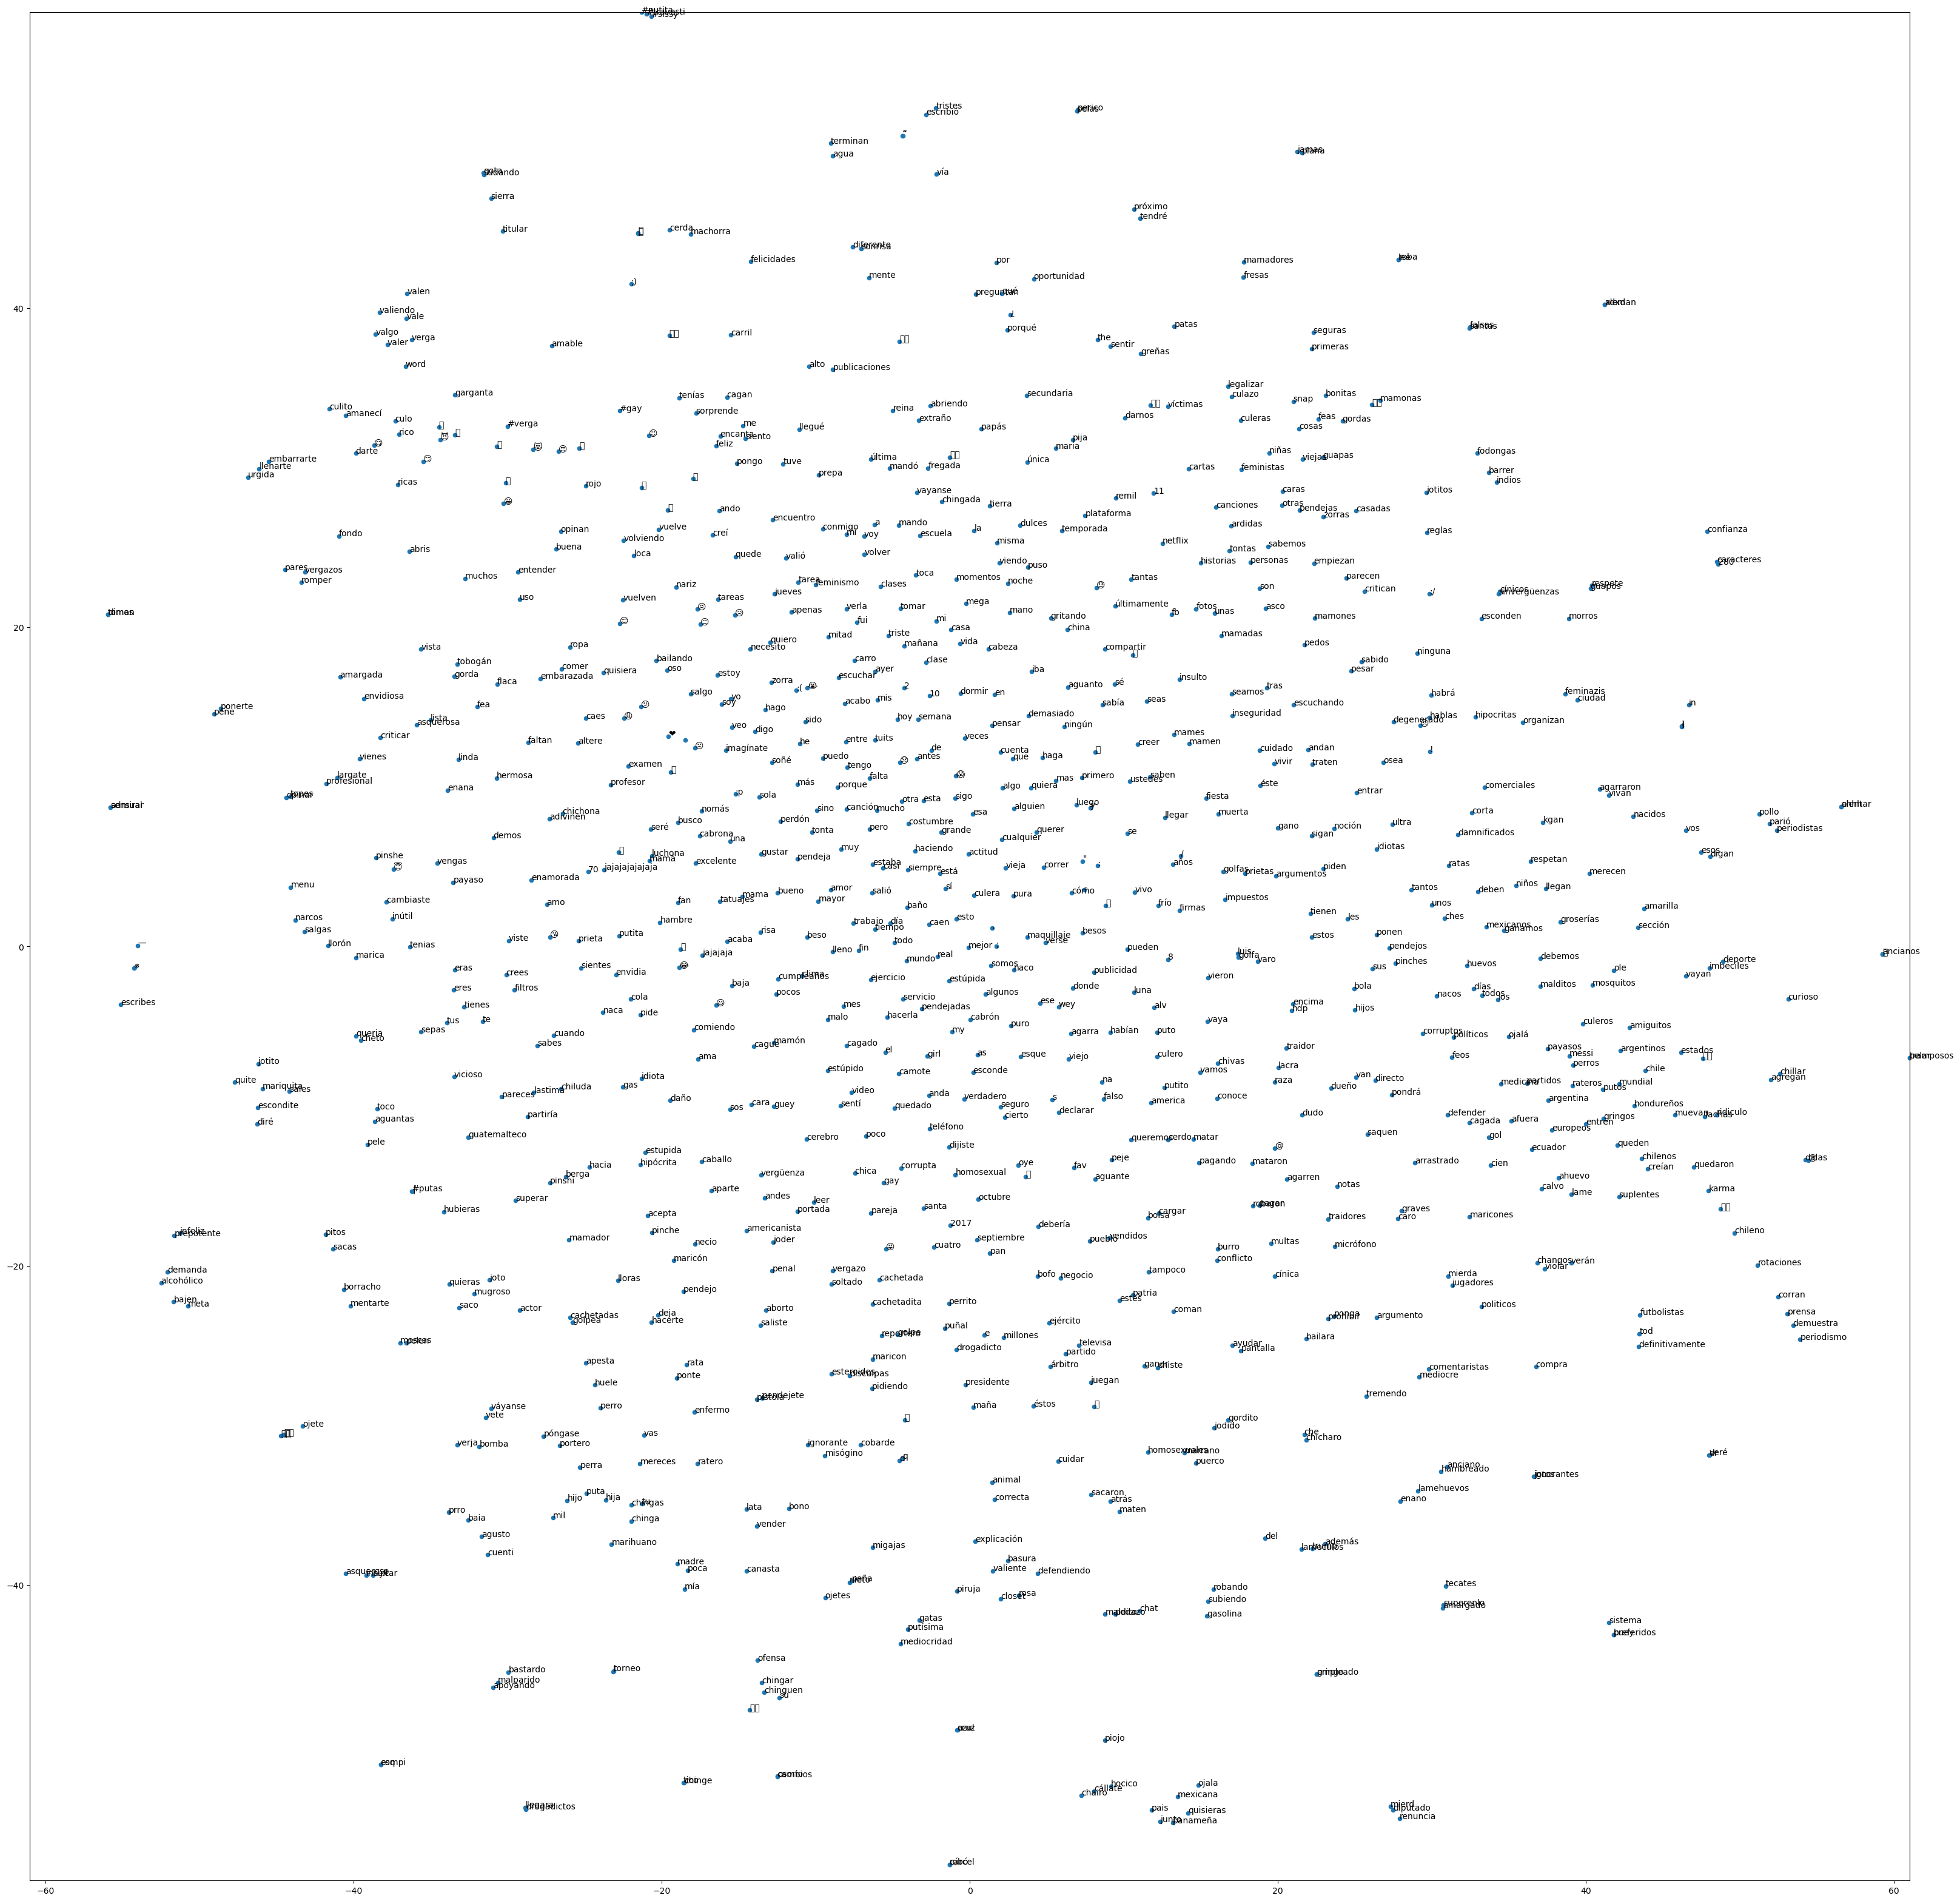

In [82]:
max_x = np.amax(reduced_matrix, axis=0)[0]
max_y = np.amax(reduced_matrix, axis=0)[1]
plt.figure(figsize=(40, 40), dpi=100); plt.xlim((-max_x,max_x)); plt.ylim((-max_y,max_y))
plt.scatter(reduced_matrix[:, 0], reduced_matrix[:, 1], 20);
for idx, word in enumerate(words[:]):
    x = reduced_matrix[idx, 0]
    y = reduced_matrix[idx, 1]
    plt.annotate(word, (x,y))

plt.savefig("TCOR")
plt.show()
plt.close()

## Nube de palabras chi2

In [83]:
from wordcloud import WordCloud

chi2_scores = feats.scores_
best_dict = {str(dict_indice_invertido[idx]): chi2_scores[idx] for idx in best}

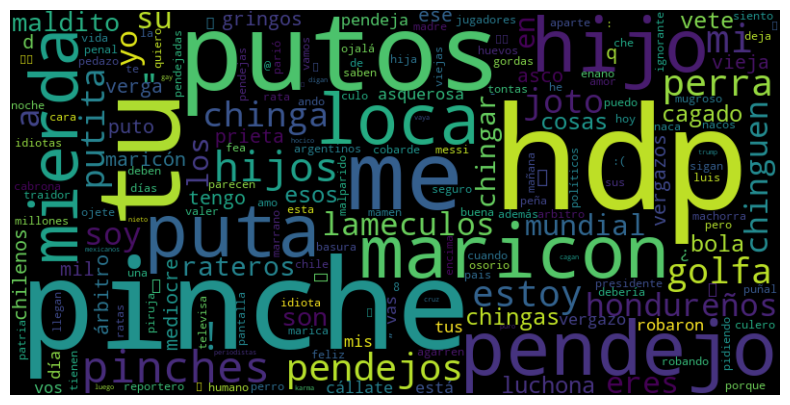

In [84]:
wordcloud = WordCloud(width=800, height=400, background_color="black").generate_from_frequencies(best_dict)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.show()